In [3]:
# from astropy.io import fits
import pickle
import numpy as np
import scipy.stats as stats
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy
from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import scipy
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import sys
import os

# 获取当前脚本的目录，并添加其上一级目录到 sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from libanaly import Plot_Background,plot_quivers,CircleCalc

In [2]:
def get_reloc_offset(dataimage):
    shape=dataimage.shape[0]
    xgrid = np.linspace(-16.3434,16.3434,shape,endpoint=False)
    ygrid = np.linspace(-16.3434,16.3434,shape,endpoint=False)
    diff = np.diff(xgrid)[0]/2.
    xgrid += diff
    ygrid += diff
    xmesh,ymesh = np.meshgrid(xgrid,ygrid,indexing='ij')

    iI = scipy.interpolate.RectBivariateSpline(xmesh[:,0],ymesh[0,:],dataimage[:,:,0])

    Rres = 10
    Rmax = 10
    Rmin = 0.2
    
    Pres = 10
    Pmax = 1 * 2*np.pi
    Pmin = 1./360. * 2*np.pi
    
    
    dr = Rmin/Rres
    dphi = Pmin/Pres

    
    r = np.arange(np.round(Rmax/Rmin)*Rres + 1)*dr
    phi = ( np.arange(np.round(Pmax/Pmin)*Pres  + 1) -Pres/2 )*dphi
    
    window = np.ones((Rres+1,Pres+1))
    window[0,:]  *= 0.5
    window[-1,:] *= 0.5
    window[:,0]  *= 0.5
    window[:,-1] *= 0.5
    
    
    
    window0 = np.ones(Pres+1)
    window0[0]  *= 0.5
    window0[-1] *= 0.5
    
    r_pk = np.zeros((17*17,len(phi)))
    r_pk_bar = np.zeros((17*17))
    sigma_r_bar = np.zeros((17*17))
    starting = int(shape/2-8)
    
    for x0 in range(17):
        for y0 in range(17):
            x_mesh = r[:,None]*np.cos(phi[None,:])+xmesh[:,0][x0+starting]
            y_mesh = r[:,None]*np.sin(phi[None,:])+ymesh[0,:][y0+starting]
            Ii = iI.ev(x_mesh,y_mesh) 
            r_pk[x0*17+y0] = np.argmax(Ii,axis=0)
            r_pk_bar[x0*17+y0] = np.mean(r_pk[x0*17+y0])
            sigma_r_bar[x0*17+y0] = np.std(r_pk[x0*17+y0])
    central = np.argmin(sigma_r_bar/r_pk_bar)
    xoff = int(central//17+starting-shape/2-1)
    yoff = int(central%17+starting-shape/2-1)
    
    return xoff,yoff

In [ ]:
# Trying to place the gaussian peak in the middle of the range of fitting.
def re_loc(counts,bins):
    counts = list(counts)
    bins = list(bins)
    if max(bins)>30:
        pi = 180
    else:
        pi =np.pi
    maxloc = np.argmax(counts)
    middleloc = round(len(counts)/2.)-1
    if maxloc < middleloc:
        offset = middleloc-maxloc
        counts = counts[-offset:]+counts[:-offset]
        bins  = [x-np.pi for x in bins[-offset:]]+bins[:-offset]
    if maxloc >middleloc:
        offset = maxloc-middleloc
        counts = counts[offset:]+counts[:offset]
        bins = bins[offset:]+[x+pi for x in bins[:offset]]
    return counts,bins

def gaussian(x,*param):
    mean = param[0]
    sigma = param[1]
    amplitude = param[2]
    return amplitude/np.sqrt(2.*np.pi*sigma*sigma)*np.exp(-np.power(x-mean,2.)/2./sigma/sigma)

# def weightedstd(xarray,counts):
#     a=np.average(xarray,weights=counts)
#     v=np.average(np.power(xarray-a,2),weights=counts)
#     return np.sqrt(v)

def fit_vonmise(d1evpaarr):
    # d1evpaarr is from -0.5pi to pi
    kappa_fit, mu_fit ,_= stats.vonmises.fit(d1evpaarr*2)  # 只拟合 kappa 和 mu
    sigma=np.sqrt(1/kappa_fit)/2
    mu_fit = mu_fit/2
    t=deepcopy(d1evpaarr)
    t[t<-0.5*np.pi+mu_fit]+=np.pi
    t[t>0.5*np.pi+mu_fit]-=np.pi
    s,p=stats.kstest(t,'norm',args=(mu_fit,sigma))
    if p>0.05:
        return mu_fit,sigma
    else:
        print()
        return np.nan,np.nan

for day in [95,96,100,101]:
    with open(f"result/230_{day}.pkl",'rb') as file1:
        data = pickle.loads(file1.read())
    chi2averhist = [pic['chi2'] for pic in data['meta_data']]
    data['meta_data'].sort(key= lambda k:(k.get('chi2',0)))
    chi2aver = deepcopy(data['meta_data'])


    # badset = []
    len_top = 1572
    # for i in range(64):
    #     for j in range(64):
    #         badset.append((i,j))

    theta_mean = np.zeros((64,64))
    theta_std = np.zeros((64,64))
    theta_all = np.zeros((64,64))
    theta_data = np.zeros((len_top,64,64))
    I_data = np.zeros((len_top,64,64))
    Q_data = np.zeros((len_top,64,64))
    U_data = np.zeros((len_top,64,64))
    All_data = np.zeros((len_top,64,64,4))


    All_data[:,:,:,0]=np.transpose(data['I_data'][::-1][:,:,:len_top],(2,0,1))
    All_data[:,:,:,1]=np.transpose(data['Q_data'][::-1][:,:,:len_top],(2,0,1))
    All_data[:,:,:,2]=np.transpose(data['U_data'][::-1][:,:,:len_top],(2,0,1))
    All_data[:,:,:,0]=np.rot90(All_data[:,:,:,0],k=-1,axes=(1,2))
    All_data[:,:,:,1]=-np.rot90(All_data[:,:,:,1],k=-1,axes=(1,2))
    All_data[:,:,:,2]=-np.rot90(All_data[:,:,:,2],k=-1,axes=(1,2)) # 这里的旋转是为了和正常的图保持一致
    theta_data=0.5*np.arctan2(All_data[:,:,:,2],All_data[:,:,:,1]) # degree
    theta_data=CircleCalc.circle_sub_evpa(theta_data,theta_data[0])+theta_data[0]
    theta_data=theta_data*180./np.pi # degree

    # for (i,j) in badset:
    #     All_data[i][j][0] = data['I_data'][-i][j][:len_top]
    #     All_data[i][j][1] = data['Q_data'][-i][j][:len_top]
    #     All_data[i][j][2] = data['U_data'][-i][j][:len_top]

    #     I_data[i][j] = data['I_data'][-i][j][:len_top]
    #     Q_data[i][j] = data['Q_data'][-i][j][:len_top]
    #     U_data[i][j] = data['U_data'][-i][j][:len_top]
    #     theta_data[i][j]=(180./np.pi)*0.5*np.arctan2(U_data[i][j],Q_data[i][j])
        

    


    for bins_i in [10]: #,6,4,14]:
        res_arr=np.apply_along_axis(fit_gaussian,2,theta_data,bins_i)
        theta_mean=res_arr[:,:,0]
        theta_std=np.abs(res_arr[:,:,1])
        theta_all=res_arr[:,:,2]*np.sqrt(2.*np.pi*theta_std)

    # for bins_i in [10,6,4,14]:
    #     for (i,j) in deepcopy(badset):
    #         if (i,j)==(1,0):
    #             print("debug")
    #         counts,bins = np.histogram(np.array(theta_data[i][j]),bins=10*bins_i) #10*(4)
    #         #counts,bins =re_loc(counts,bins)
    #         xarray = np.array([(bins[i]+bins[i+1])/2 for i in range(len(bins)-1)])
    #         popt,pcov = optimize.curve_fit(gaussian,xarray,counts,p0=[xarray[np.argmax(counts)],5,len_top],maxfev=500000,gtol=1e-10)
    #         if abs(pcov[0][0])>abs(popt[0]) or abs(pcov[1][1])>abs(popt[1]):
    #             print(f'badfit at {i},{j}')
    #             continue
    #         else:
    #             theta_mean[i][j] = popt[0]
    #             theta_std[i][j] = abs(popt[1])
    #             theta_all[i][j] = popt[2]*np.sqrt(2.*np.pi*abs(popt[1]))
    #             badset.remove((i,j))
    #             continue
    #     print(f'First round finished, badset length:{len(badset)}')

    #     for (i,j) in deepcopy(badset):
    #         if (i,j)==(1,0):
    #             print("debug")
    #         counts,bins = np.histogram(np.array(theta_data[i][j]),bins=10*bins_i)
    #         counts,bins =re_loc(counts,bins)
    #         xarray = np.array([(bins[i]+bins[i+1])/2 for i in range(len(bins)-1)])
    #         popt,pcov = optimize.curve_fit(gaussian,xarray,counts,p0=[xarray[np.argmax(counts)],5,len_top],maxfev=500000,gtol=1e-10)
    #         if abs(pcov[0][0])>abs(popt[0]) or abs(pcov[1][1])>abs(popt[1]):
    #             print(f'badfit at {i},{j}')
    #             continue
    #         else:
    #             theta_mean[i][j] = popt[0]
    #             theta_std[i][j] = abs(popt[1])
    #             theta_all[i][j] = popt[2]*np.sqrt(2.*np.pi*abs(popt[1]))
    #             badset.remove((i,j))
    #             continue
    #     print(f'Re_location round finished, badset length:{len(badset)}')
    
    

    
    
    
    
    

    All_data_mean = np.mean(All_data,axis=3)
    # a = ImageS(All_data_mean)
    # xoff,yoff = a.Re_loc(output=True)
    xoff,yoff  = get_reloc_offset(All_data_mean)

    bigset = np.zeros((2,64+16,64+16))
    bigset2=np.zeros((64+16,64+16,4))
    bigset3=np.zeros((64+16,64+16,4,len_top))

    bigset[0, 9:64+9, 9:64+9] = theta_mean
    bigset[1, 9:64+9, 9:64+9] = theta_std
    bigset2[9:64+9, 9:64+9] = All_data_mean
    bigset3[9:64+9, 9:64+9] = All_data
    
    theta_mean[:] = bigset[0, 9 + xoff:64+9 + xoff, 9 + yoff:64+9 + yoff]
    theta_std[:] = bigset[1, 9 + xoff:64+9 + xoff, 9 + yoff:64+9 + yoff]
    All_data_mean[:]=bigset2[9 + xoff:64+9 + xoff, 9 + yoff:64+9 + yoff]
    All_data[:]=bigset3[9 + xoff:64+9 + xoff, 9 + yoff:64+9 + yoff]
    
    np.save(f'{day}_all_data_mean',All_data_mean)
    np.save(f'{day}_all_data',All_data)

    # for i in range(64):
    #     for j in range(64):
    #         bigset[0][i+9][j+9] = theta_mean[i][j]
    #         bigset[1][i+9][j+9] = theta_std[i][j]
    # for i in range(64):
    #     for j in range(64):
    #         theta_mean[i][j] = bigset[0][i+9+xoff][j+9+yoff]
    #         theta_std[i][j] = bigset[1][i+9+xoff][j+9+yoff]

    P_mean = np.sqrt(All_data_mean[:,:,1]**2+All_data_mean[:,:,2]**2)
    np.savez(f'{day}',theta_mean,theta_std,P_mean,All_data_mean[:,:,0])
    
    
    



badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit


/home/canoziia/MyProject/PHYS/EHT_ZC/.venv/lib/python3.12/site-packages/scipy/optimize/_minpack_py.py:499: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit

/home/canoziia/MyProject/PHYS/EHT_ZC/.venv/lib/python3.12/site-packages/scipy/optimize/_minpack_py.py:499: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit
badfit


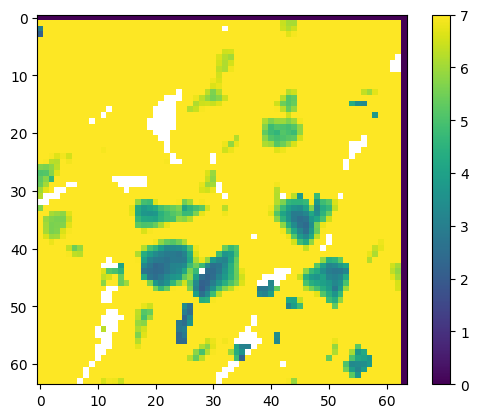

In [131]:
plt.clf()
plt.imshow(theta_std)
plt.colorbar()
plt.clim(0,7)
plt.show()

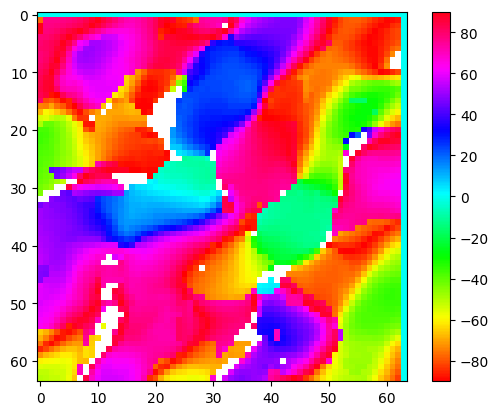

In [107]:
plt.clf()
plt.imshow(np.arcsin(np.sin(theta_mean/180*np.pi))/np.pi*180,cmap="hsv")
plt.colorbar()

In [140]:
import importlib

import libanaly
# 修改了 my_package 后，使用 reload 来重新加载它
importlib.reload(libanaly)
from libanaly import Plot_Background,plot_quivers,CircleCalc

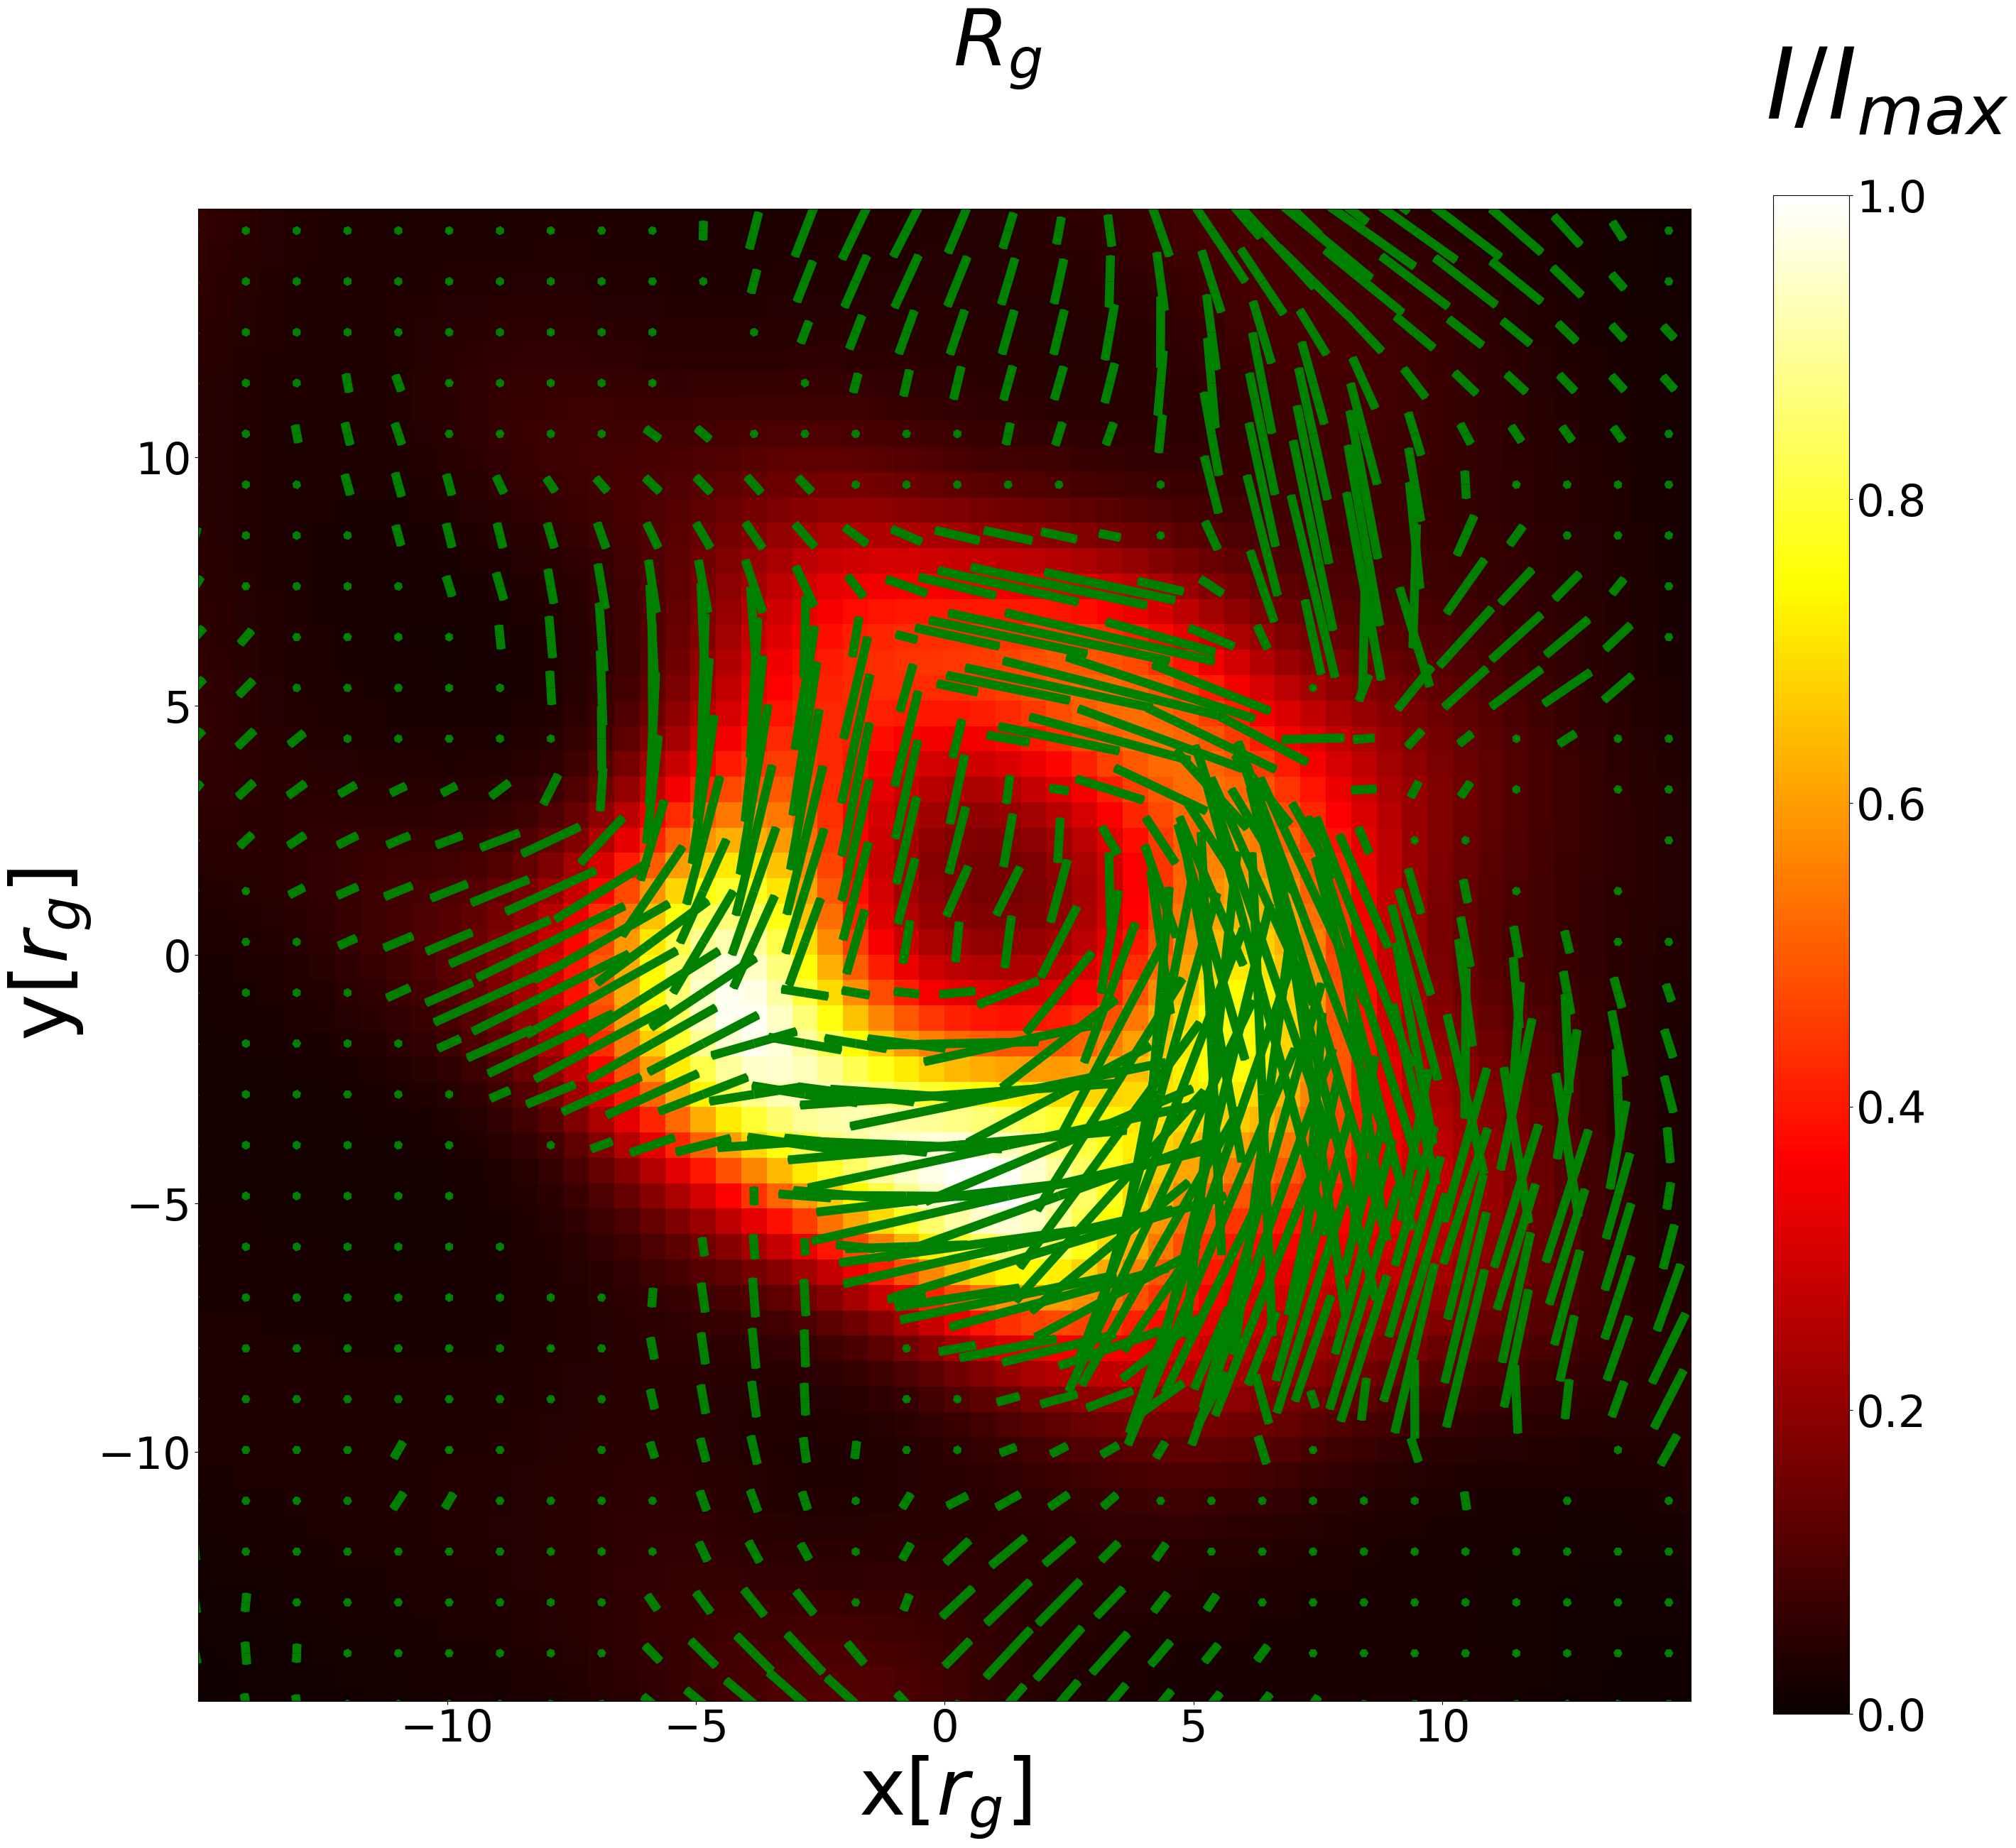

In [142]:
figure,ax0=plot_quivers(All_data_mean[:,:,0],P_mean,theta_mean/180*np.pi)
figure

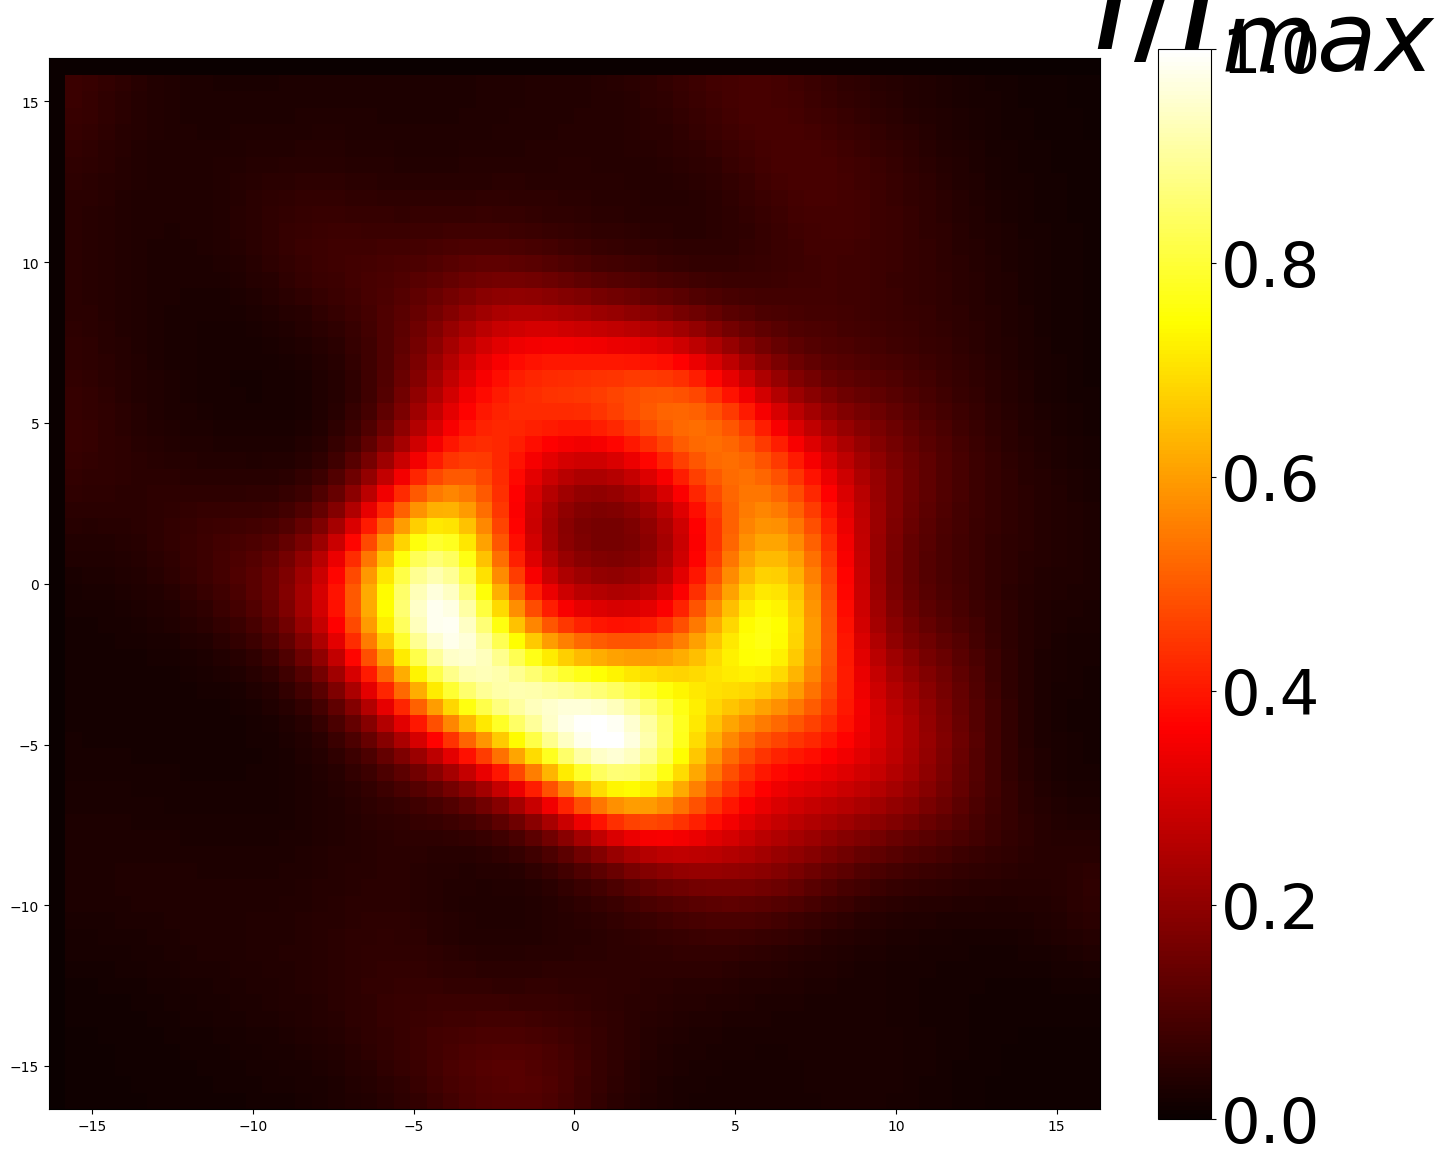

In [132]:
figure,ax0=plt.subplots(figsize=(15,15))
Plot_Background(figure,ax0,All_data_mean[:,:,0])
figure

In [75]:
def circle_mean(m):
    base=m[:,:,0]
    # baseexpand=np.repeat(base[:, :, np.newaxis], m.shape[2], axis=2)
    s=CircleCalc.circle_sub(m,base[:, :, np.newaxis])
    sm=np.mean(s,axis=2)
    return base+sm

def evpa_mean(m):
    return circle_mean(2*m)/2

In [87]:
All_data[:,:,0,:]=data['I_data'][::-1][:,:,:len_top]
All_data[:,:,1,:]=data['Q_data'][::-1][:,:,:len_top]
All_data[:,:,2,:]=data['U_data'][::-1][:,:,:len_top]
# All_data[:,:,3,:]=data['V_data'][::-1][:,:,:len_top]


All_data[:,:,0,:]=np.rot90(All_data[:,:,0,:],k=-1,axes=(0,1))
All_data[:,:,1,:]=-np.rot90(All_data[:,:,1,:],k=-1,axes=(0,1))
All_data[:,:,2,:]=-np.rot90(All_data[:,:,2,:],k=-1,axes=(0,1))


EVPA=evpa_mean(0.5*np.arctan2(All_data[:,:,2,:],All_data[:,:,1,:]))
P=np.mean(np.sqrt(All_data[:,:,1,:]**2+All_data[:,:,2,:]**2),axis=2)
I=np.mean(All_data[:,:,0,:],axis=2)

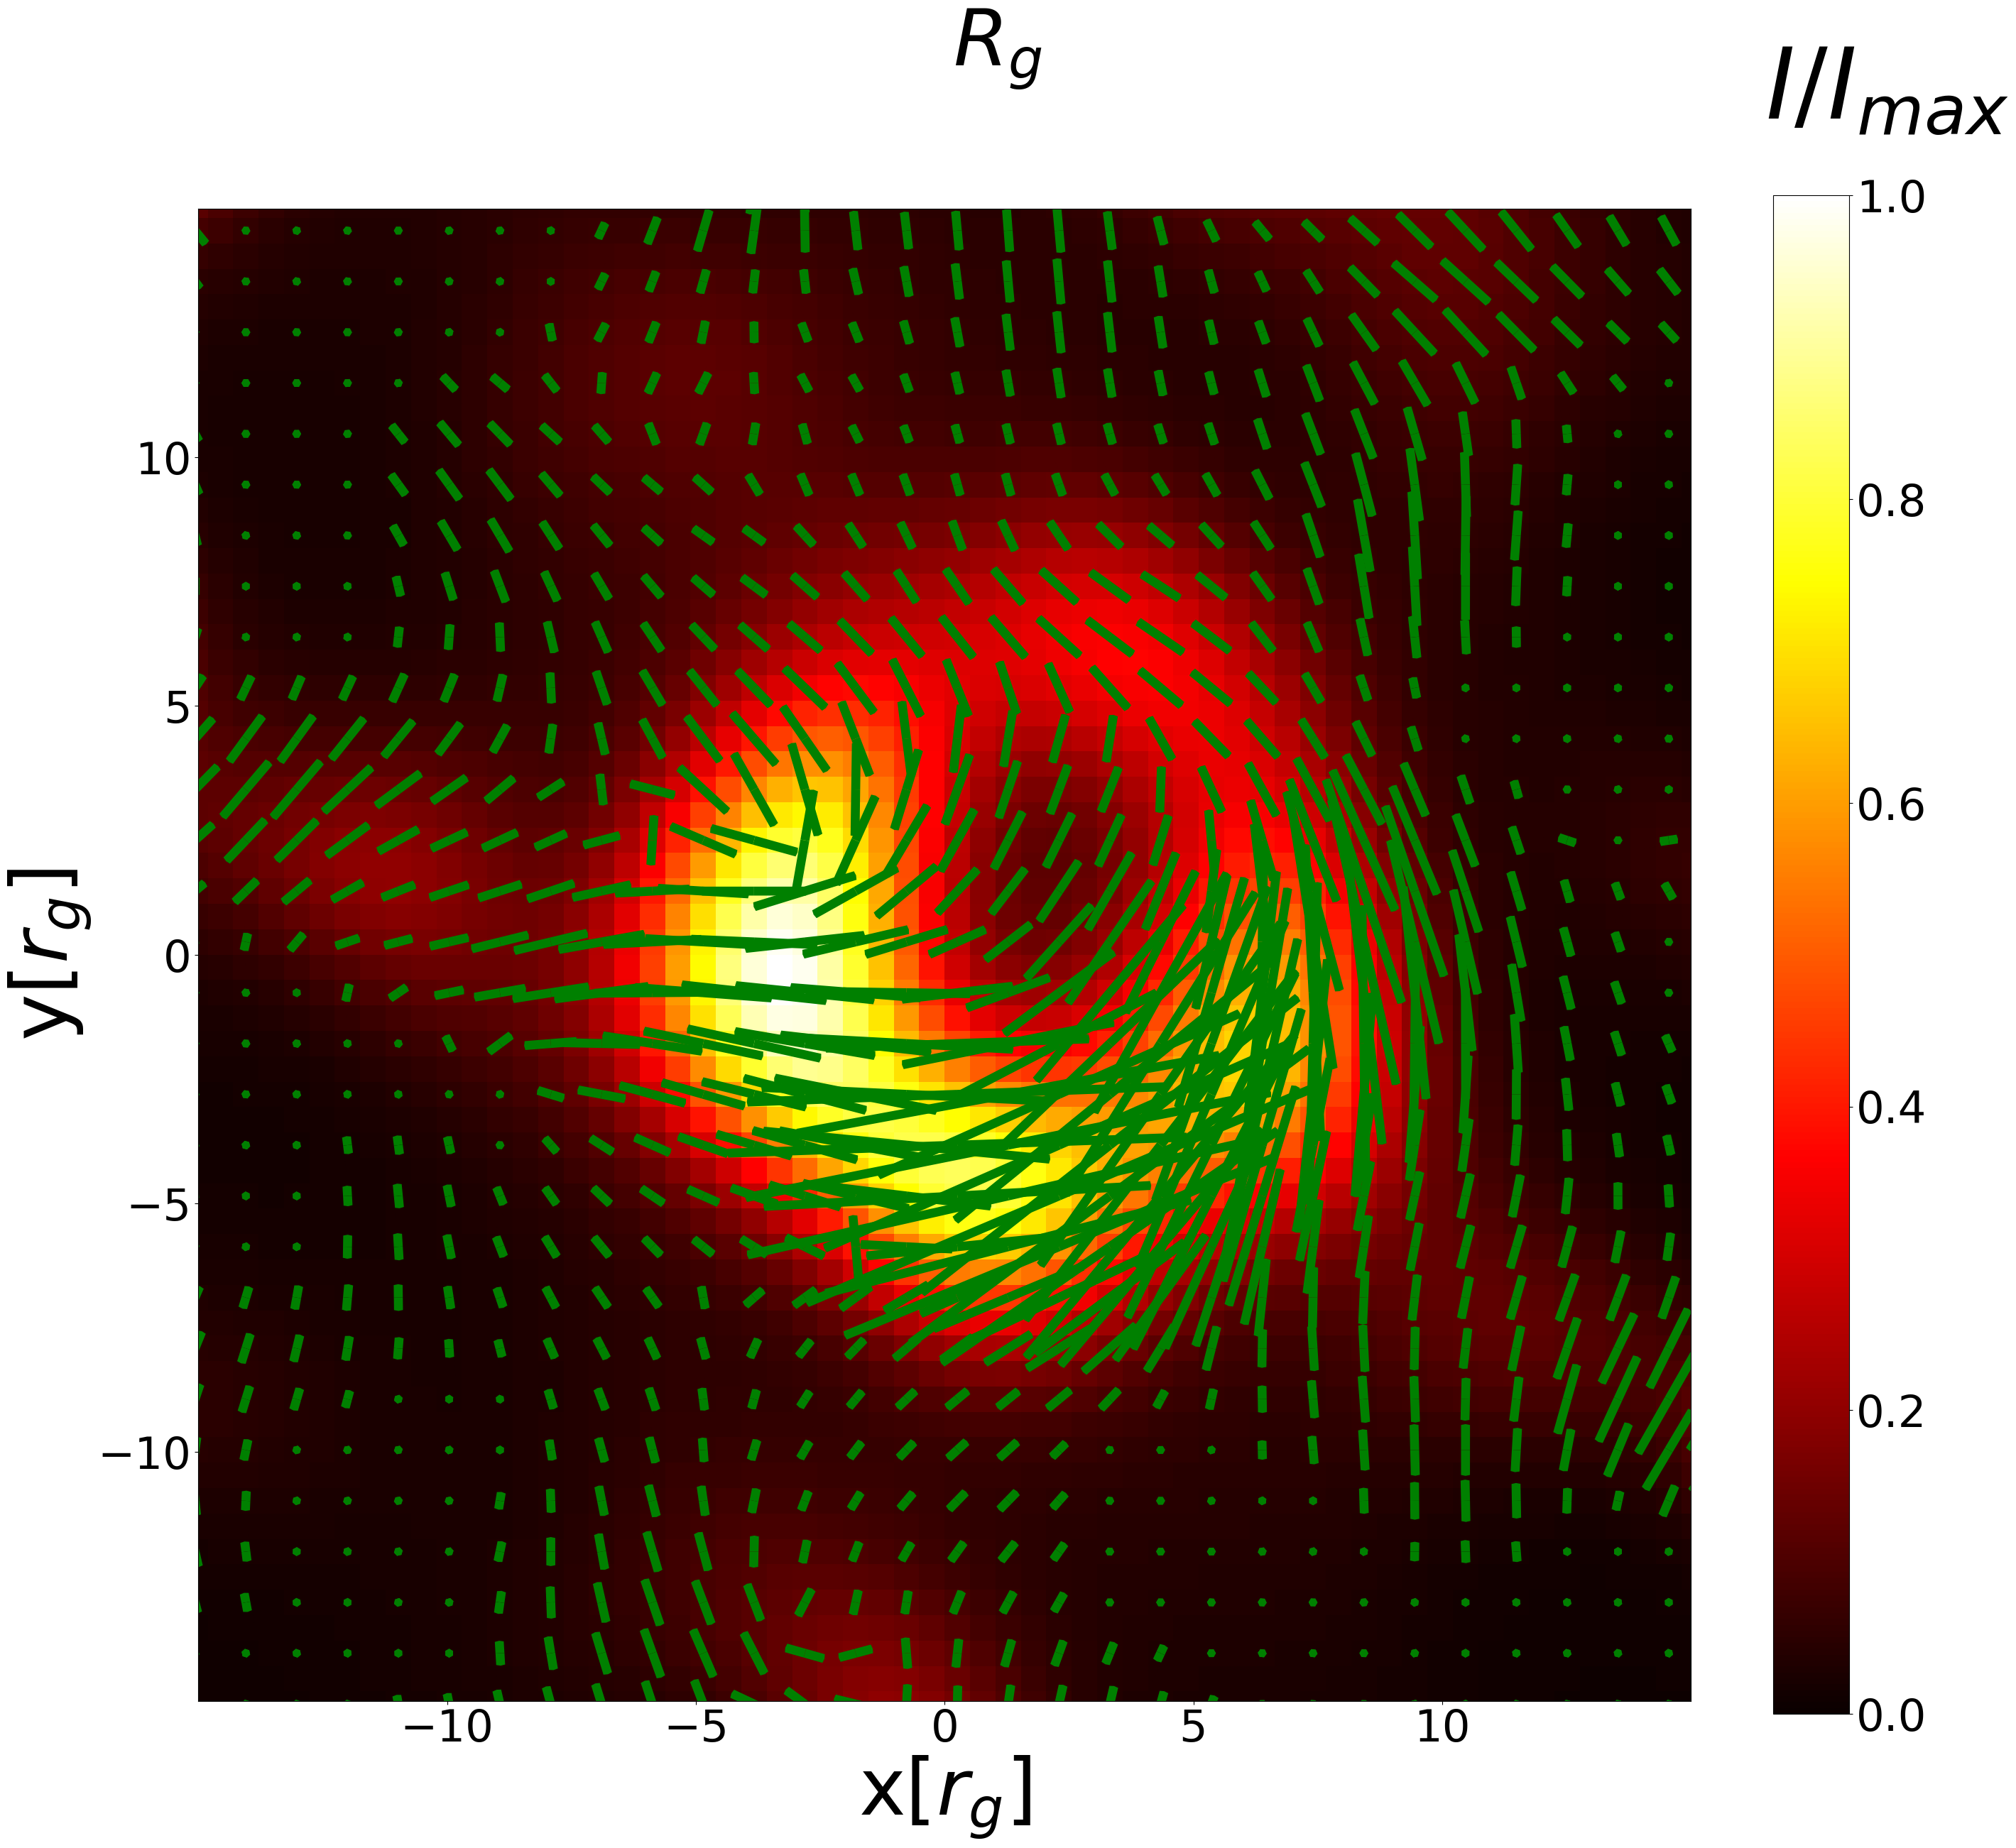

In [88]:
figure,ax0=plot_quivers(I,P,EVPA)
figure

/home/canoziia/MyProject/PHYS/EHT_ZC/libanaly.py:50: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  figure, ax0 = plt.subplots(figsize=(30, 30))


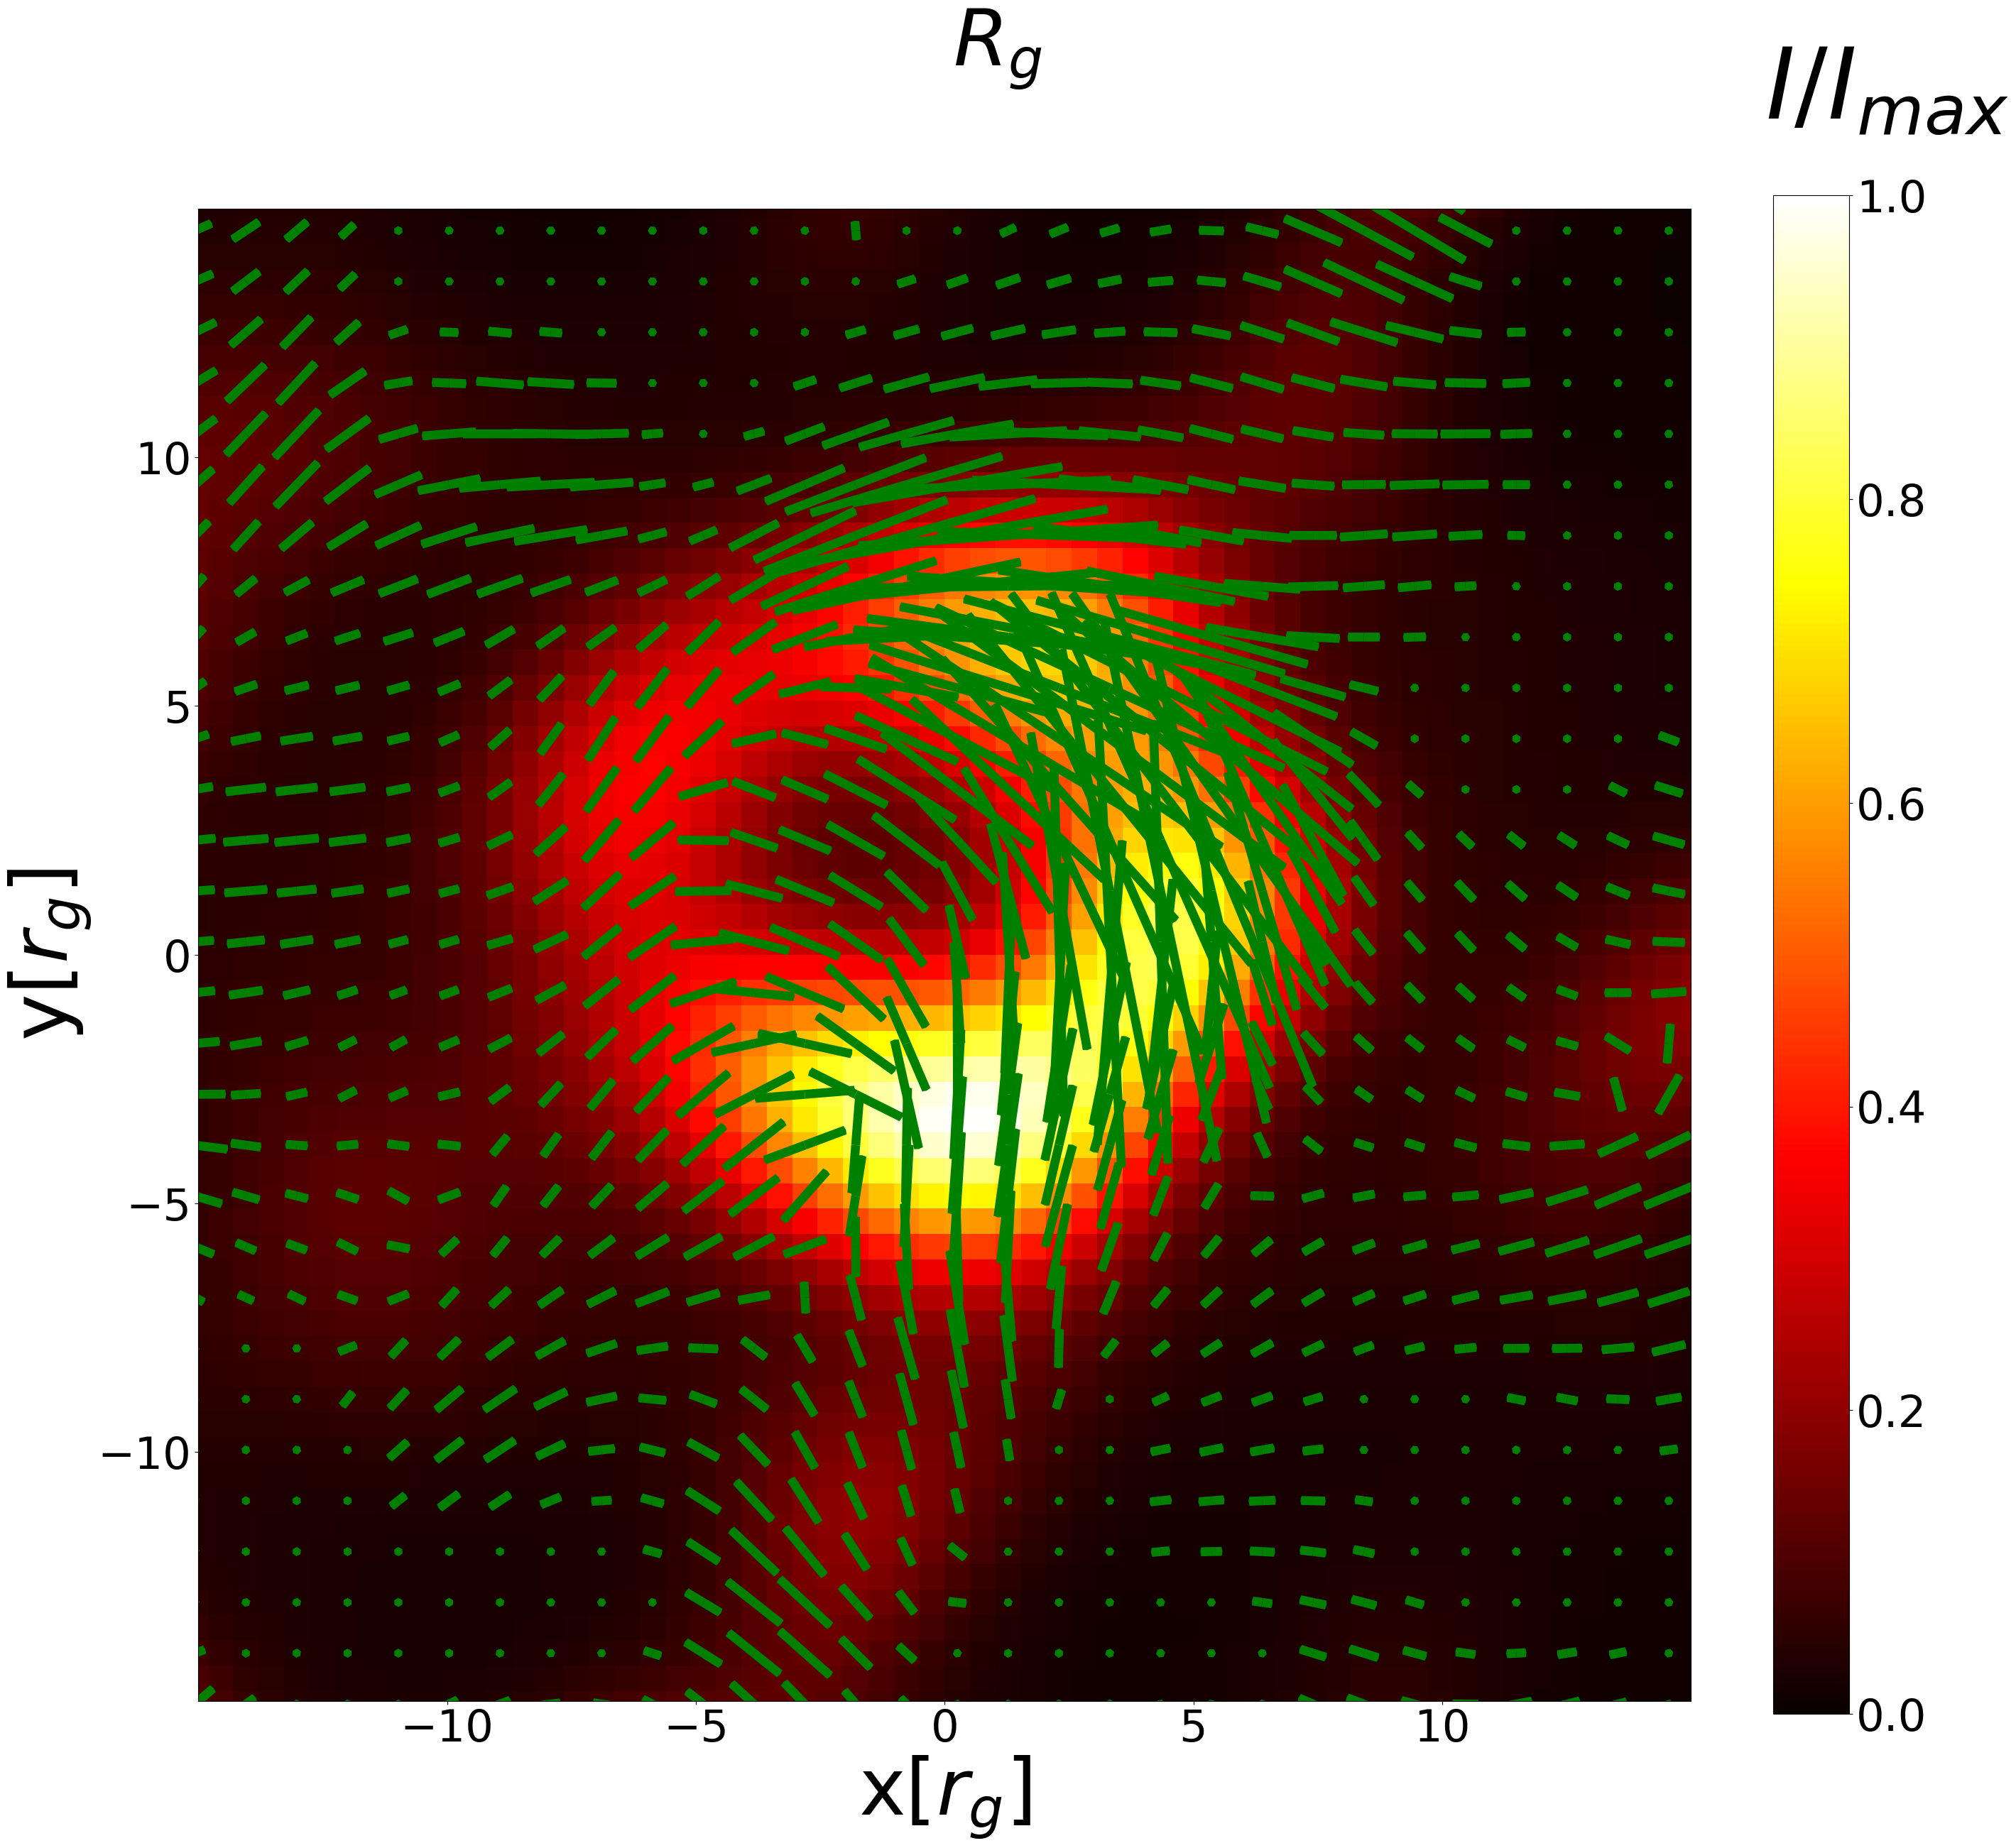

In [86]:
figure,ax0=plot_quivers(I,P,EVPA)
figure

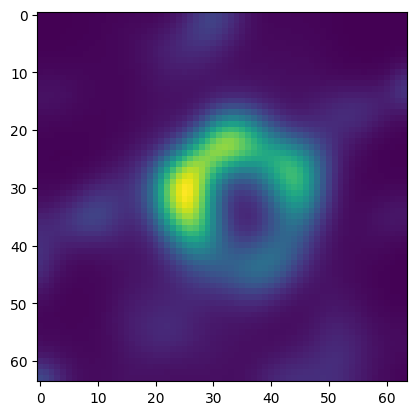

In [7]:
plt.imshow(np.mean(data['I_data'][:,:,:len_top],axis=2))